# 🛰️ Project Sentinel — Hazardous Asteroid Prediction AI
**Supervised binary classification on NASA Near-Earth-Object (NEO) close-approach data**

**Highlights**
- Leakage-safe evaluation: the same asteroid appears several times, so every split is **grouped by asteroid ID**
- Class imbalance (~10% hazardous) handled with class weighting, PR-AUC and **recall-first threshold tuning**
- Explainability with permutation importance + **SHAP**
- Deployed as a saved model + **Gradio web app**
- Honest finding: the label depends on an orbital quantity (MOID) that is *not* in this CSV, which caps achievable performance

**Pipeline:** Preprocessing → EDA → Feature Engineering → Modeling → Explainability → Deployment

In [1]:
%pip install -q xgboost shap gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, shap

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score, f1_score,
                             fbeta_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

---
## Phase 1 — Data Preparation & Preprocessing

In [3]:
import glob
# If auto-detect fails, set the path yourself, e.g. DATA_PATH = r"C:\Users\you\Downloads\neo__3_.csv"
DATA_PATH = None
if DATA_PATH is None:
    hits = glob.glob("*neo*.csv") + glob.glob("**/*neo*.csv", recursive=True) + glob.glob("/content/*neo*.csv")
    DATA_PATH = hits[0] if hits else None
assert DATA_PATH, f"Dataset not found. Current folder: {os.getcwd()}. Copy the CSV here or set DATA_PATH."

df = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH, "| Shape:", df.shape)
df.head()

Using: neo (3).csv | Shape: (90836, 10)


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


In [4]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique asteroids (id):", df['id'].nunique(), "| total close-approach rows:", len(df))
print("\nUnique values per column:\n", df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  str    
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  str    
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), str(2)
memory usage: 7.1 MB

Missing values per column:
 id                    0
name                  0
est_diameter_min      0
est_diameter_max      0
relative_velocity     0
miss_distance         0
orbiting_body         0
sentry_object         0
absolute_magnitude    0
ha

**Findings & decisions**
- **No missing values** and no duplicate rows → nothing to impute.
- `orbiting_body` and `sentry_object` have a **single constant value** → zero information → dropped.
- `id` / `name` are identifiers, not predictors → dropped from the features, **but `id` is kept as the grouping key**: 90,836 rows belong to only ~27k asteroids (repeated close approaches). Random splitting would put the *same asteroid* in train and test and inflate scores, so all splits below are grouped by `id`.
- Target `hazardous` is boolean → cast to 0/1. No categorical features remain to encode.
- Units: diameter in km, velocity in km/h, miss distance in km.
- Scaling is applied **inside a pipeline** only for the scale-sensitive model (Logistic Regression), so there is no leakage from the test set.

In [5]:
df["hazardous"] = df["hazardous"].astype(int)
groups = df["id"].copy()

const_cols = [c for c in df.columns if df[c].nunique() == 1]
drop_cols = const_cols + ["name"]
print("Dropping:", drop_cols, "(id kept separately as group key)")
data = df.drop(columns=drop_cols + ["id"])
data.describe().T

Dropping: ['orbiting_body', 'sentry_object', 'name'] (id kept separately as group key)


,count,mean,std,min,25%,50%,75%,max
est_diameter_min,90836.0,1.274321e-01,2.985112e-01,0.000609,1.925551e-02,4.836765e-02,1.434019e-01,3.789265e+01
est_diameter_max,90836.0,2.849469e-01,6.674914e-01,0.001362,4.305662e-02,1.081534e-01,3.206564e-01,8.473054e+01
relative_velocity,90836.0,4.806692e+04,2.529330e+04,203.346433,2.861902e+04,4.419012e+04,6.292360e+04,2.369901e+05
miss_distance,90836.0,3.706655e+07,2.235204e+07,6745.532516,1.721082e+07,3.784658e+07,5.654900e+07,7.479865e+07
absolute_magnitude,90836.0,2.352710e+01,2.894086e+00,9.230000,2.134000e+01,2.370000e+01,2.570000e+01,3.320000e+01
hazardous,90836.0,9.731824e-02,2.963923e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


---
## Phase 2 — Exploratory Data Analysis

hazardous
0    81996
1     8840
Name: count, dtype: int64 
Hazardous share: 9.73%
Hazardous share by unique asteroid: 7.92%


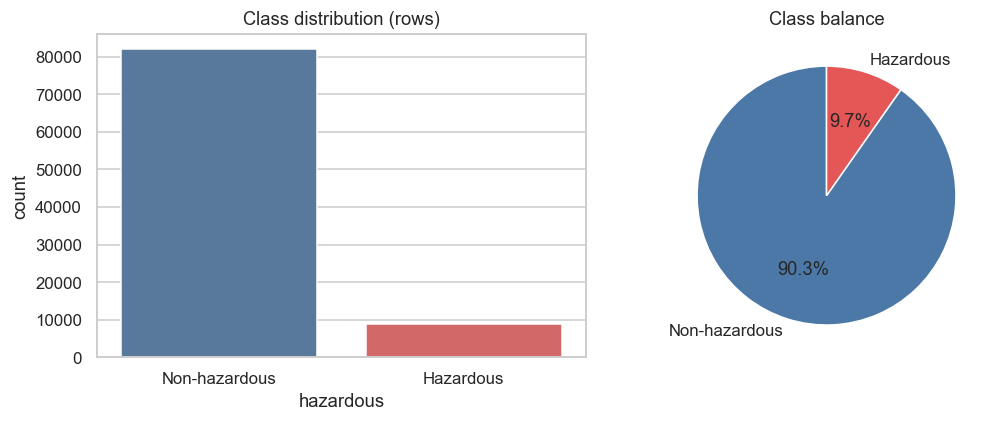

A model that always says 'non-hazardous' scores 90.3% accuracy -> accuracy is the wrong metric.


In [6]:
counts = data["hazardous"].value_counts()
print(counts, "\nHazardous share: %.2f%%" % (100 * counts[1] / len(data)))
print("Hazardous share by unique asteroid: %.2f%%" % (100 * df.groupby("id")["hazardous"].max().mean()))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="hazardous", data=data, ax=ax[0], palette=["#4C78A8", "#E45756"])
ax[0].set_title("Class distribution (rows)"); ax[0].set_xticklabels(["Non-hazardous", "Hazardous"])
ax[1].pie(counts, labels=["Non-hazardous", "Hazardous"], autopct="%1.1f%%", colors=["#4C78A8", "#E45756"], startangle=90)
ax[1].set_title("Class balance"); plt.tight_layout(); plt.show()
print("A model that always says 'non-hazardous' scores %.1f%% accuracy -> accuracy is the wrong metric." % (100 * counts[0] / len(data)))

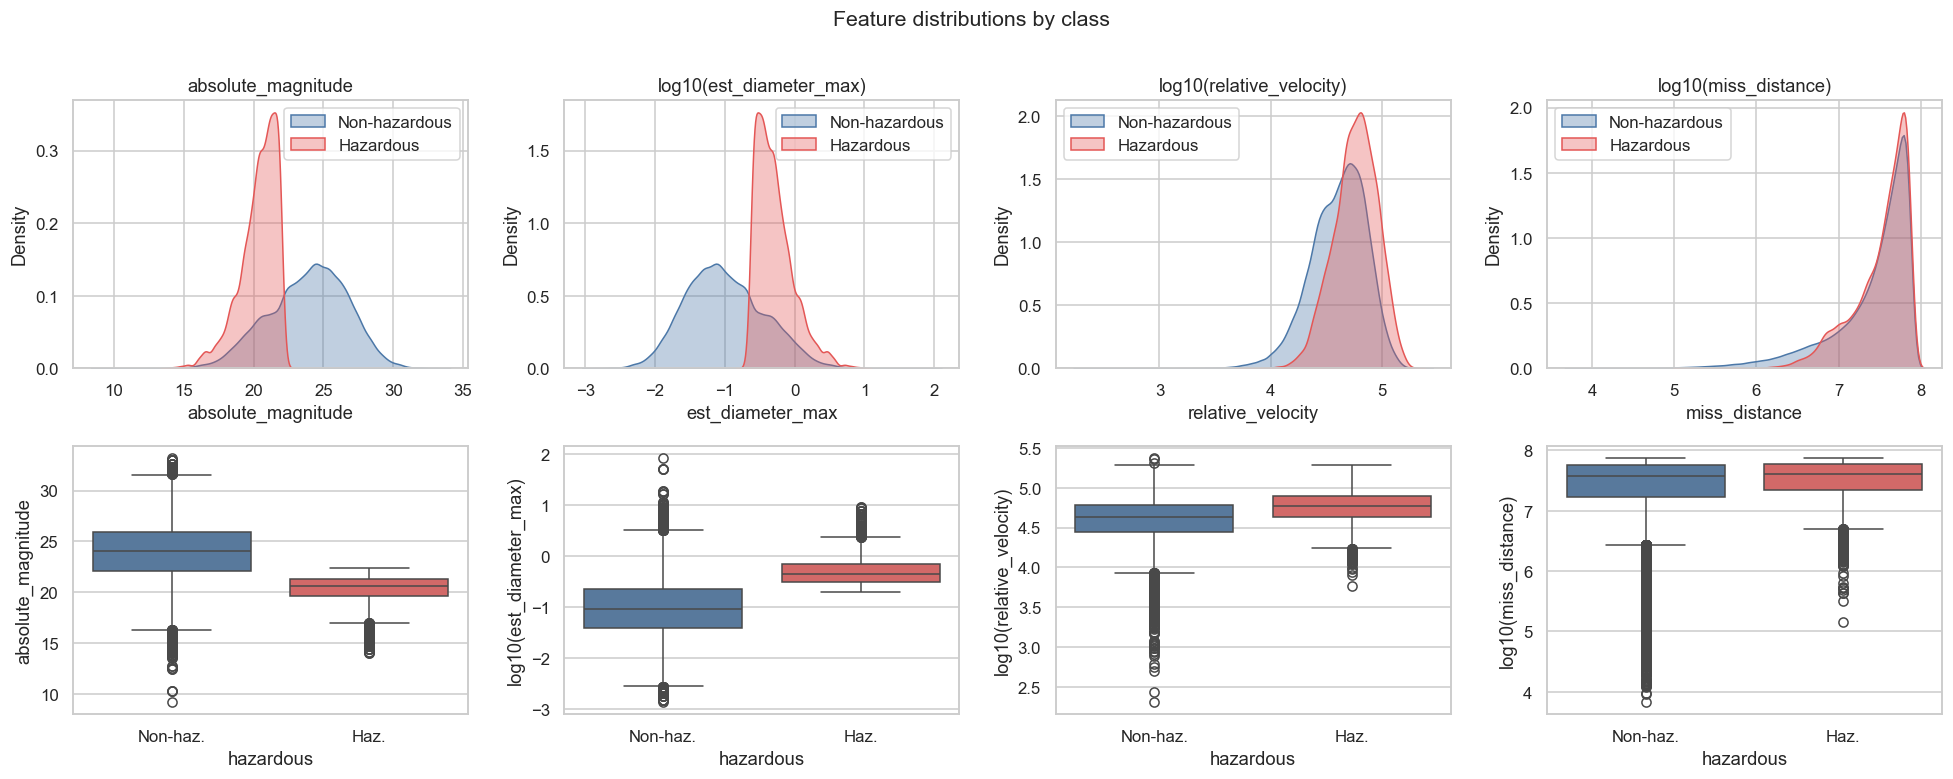

In [7]:
feats = ["absolute_magnitude", "est_diameter_max", "relative_velocity", "miss_distance"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, f in enumerate(feats):
    x = data[f] if f == "absolute_magnitude" else np.log10(data[f])
    lab = f if f == "absolute_magnitude" else f"log10({f})"
    for cls, col in [(0, "#4C78A8"), (1, "#E45756")]:
        sns.kdeplot(x[data.hazardous == cls], ax=axes[0, i], color=col, fill=True, alpha=.35,
                    label="Hazardous" if cls else "Non-hazardous", common_norm=False)
    axes[0, i].set_title(lab); axes[0, i].legend()
    sns.boxplot(x="hazardous", y=x, data=data, ax=axes[1, i], palette=["#4C78A8", "#E45756"])
    axes[1, i].set_xticklabels(["Non-haz.", "Haz."]); axes[1, i].set_ylabel(lab)
plt.suptitle("Feature distributions by class", y=1.01, fontsize=14); plt.tight_layout(); plt.show()

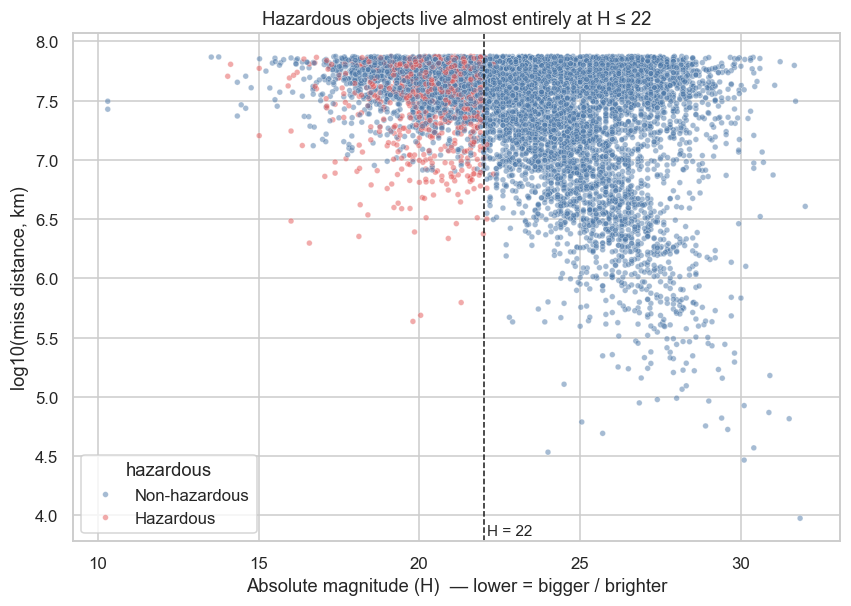

Hazardous rows with H <= 22: 8750 of 8840 (99.0%)
But only 30.1% of rows with H <= 22 are hazardous -> size is necessary, not sufficient.


In [8]:
# Size vs. proximity: the two intuitions from the brief, on one chart
s = data.sample(8000, random_state=SEED)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=s["absolute_magnitude"], y=np.log10(s["miss_distance"]), hue=s["hazardous"].map({0: "Non-hazardous", 1: "Hazardous"}),
                palette={"Non-hazardous": "#4C78A8", "Hazardous": "#E45756"}, alpha=.5, s=14)
plt.axvline(22, color="k", ls="--", lw=1); plt.text(22.1, plt.ylim()[0] + .05, "H = 22", fontsize=10)
plt.xlabel("Absolute magnitude (H)  — lower = bigger / brighter"); plt.ylabel("log10(miss distance, km)")
plt.title("Hazardous objects live almost entirely at H ≤ 22"); plt.show()

above = data[data.absolute_magnitude <= 22]
print("Hazardous rows with H <= 22: %d of %d (%.1f%%)" % (above.hazardous.sum(), data.hazardous.sum(), 100 * above.hazardous.sum() / data.hazardous.sum()))
print("But only %.1f%% of rows with H <= 22 are hazardous -> size is necessary, not sufficient." % (100 * above.hazardous.mean()))

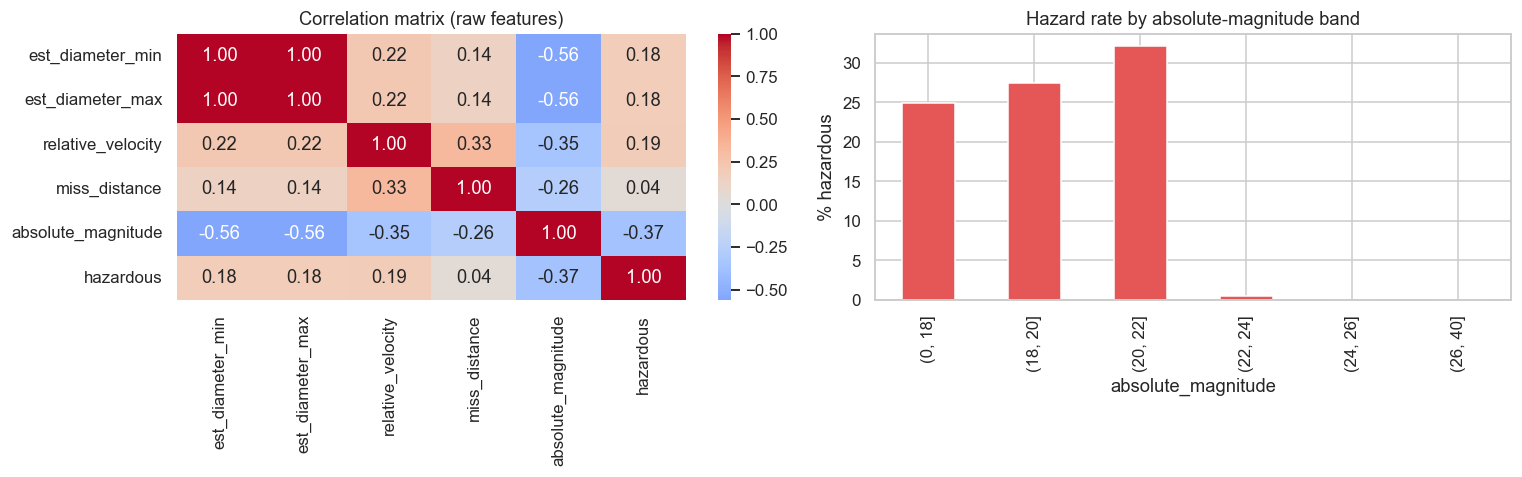

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0]); ax[0].set_title("Correlation matrix (raw features)")
bins = pd.cut(data["absolute_magnitude"], bins=[0, 18, 20, 22, 24, 26, 40])
data.groupby(bins)["hazardous"].mean().mul(100).plot(kind="bar", color="#E45756", ax=ax[1])
ax[1].set_ylabel("% hazardous"); ax[1].set_title("Hazard rate by absolute-magnitude band"); plt.tight_layout(); plt.show()

**EDA insights**
1. Severe imbalance (~10% hazardous) → use PR-AUC / recall / F2 / MCC instead of accuracy.
2. Hazardous objects are **brighter/larger** (lower H) — nearly all of them have H ≤ 22 — but most H ≤ 22 objects are still *not* hazardous, so no single feature decides the label (Challenge 1).
3. The two diameter columns are perfectly correlated with each other and (in log scale) with H → redundant (handled in Phase 3).
4. Velocity and miss distance overlap heavily between classes → weak individual signals; interactions matter (Challenge 2).

---
## Phase 3 — Feature Engineering & Selection

In [10]:
# 1) Redundancy check: NASA derives diameter from H using an assumed albedo, so diameter carries no new information
r = np.corrcoef(np.log10(data.est_diameter_max), data.absolute_magnitude)[0, 1]
r2 = np.corrcoef(data.est_diameter_min, data.est_diameter_max)[0, 1]
print(f"corr(log10 diameter_max, H) = {r:.4f} | corr(diameter_min, diameter_max) = {r2:.4f}")
print("ratio max/min is constant:", (data.est_diameter_max / data.est_diameter_min).round(4).nunique() <= 3)

corr(log10 diameter_max, H) = -1.0000 | corr(diameter_min, diameter_max) = 1.0000
ratio max/min is constant: True


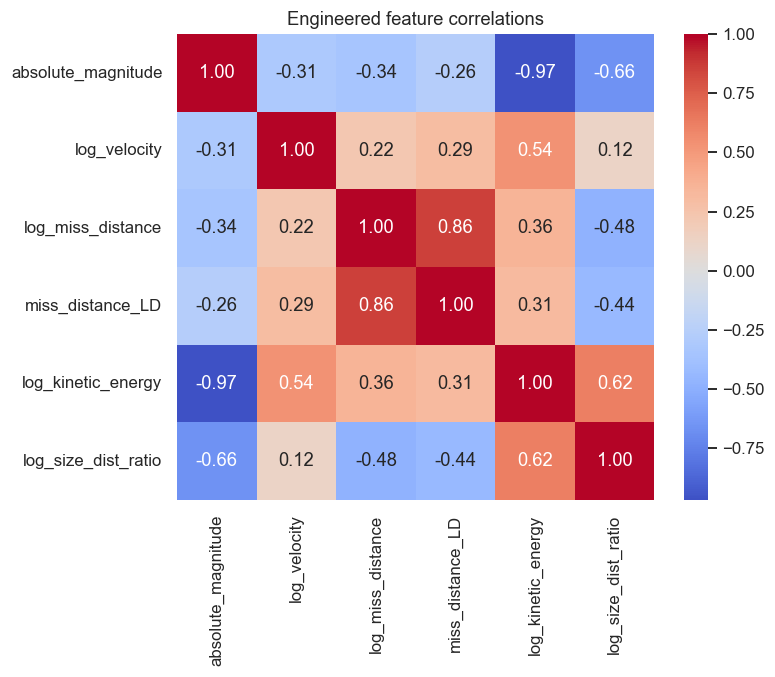

Mutual information with target:
 absolute_magnitude     0.1372
log_kinetic_energy     0.1051
log_size_dist_ratio    0.0602
log_velocity           0.0222
log_miss_distance      0.0029
miss_distance_LD       0.0028
dtype: float64


In [11]:
LD_KM = 384_400  # mean Earth–Moon distance, km
fe = pd.DataFrame(index=data.index)
fe["absolute_magnitude"]   = data["absolute_magnitude"]
fe["log_velocity"]         = np.log10(data["relative_velocity"])
fe["log_miss_distance"]    = np.log10(data["miss_distance"])
fe["miss_distance_LD"]     = data["miss_distance"] / LD_KM                                    # lunar distances (interpretable)
fe["log_kinetic_energy"]   = np.log10(data["est_diameter_max"]**3 * data["relative_velocity"]**2)  # mass ∝ d³, KE ∝ m·v²
fe["log_size_dist_ratio"]  = np.log10(data["est_diameter_max"] / data["miss_distance"])        # angular-size proxy
fe["hazardous"] = data["hazardous"]

corr = fe.drop(columns="hazardous").corr()
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Engineered feature correlations"); plt.show()

mi = pd.Series(mutual_info_classif(fe.drop(columns="hazardous").sample(20000, random_state=SEED),
                                   fe.loc[fe.drop(columns="hazardous").sample(20000, random_state=SEED).index, "hazardous"],
                                   random_state=SEED), index=corr.columns).sort_values(ascending=False)
print("Mutual information with target:\n", mi.round(4))

In [12]:
# Selection: drop features with |corr| > 0.95 against a higher-priority feature
# (log_kinetic_energy ~ H at -0.97; miss_distance_LD is just a rescaled miss distance -> duplicates)
FEATURES = ["absolute_magnitude", "log_velocity", "log_miss_distance", "log_size_dist_ratio"]
print("Dropped as redundant: est_diameter_min, est_diameter_max, miss_distance_LD, log_kinetic_energy")
print("Final features:", FEATURES)
print("Max pairwise |corr| among final features: %.2f" % corr.loc[FEATURES, FEATURES].where(~np.eye(len(FEATURES), dtype=bool)).abs().max().max())

X = fe[FEATURES].copy(); y = fe["hazardous"].copy()
print("Feature matrix:", X.shape)

Dropped as redundant: est_diameter_min, est_diameter_max, miss_distance_LD, log_kinetic_energy
Final features: ['absolute_magnitude', 'log_velocity', 'log_miss_distance', 'log_size_dist_ratio']
Max pairwise |corr| among final features: 0.66
Feature matrix: (90836, 4)


**Why these features:** `absolute_magnitude` encodes size; `log_velocity` and `log_miss_distance` encode motion and proximity (log scale tames heavy tails and helps linear models); `log_size_dist_ratio` is a size-vs-proximity interaction that mirrors the brief's example (a small, fast, close object vs. a big, distant one).
The dataset has **no orbital-element columns** (eccentricity, inclination, MOID…), so velocity and miss distance are the only orbital proxies available. An optional enrichment from NASA JPL is provided at the end of the notebook.

---
## Phase 4 — Model Development
**Strategy:** grouped 80/20 split → compare models using **grouped, stratified 5-fold out-of-fold predictions on the training set** → tune the best → pick a decision threshold that favours recall → evaluate **once** on the untouched test set.

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx]), "asteroid leakage!"
print(f"Train {X_train.shape} | Test {X_test.shape} | hazardous share train {y_train.mean():.3%}, test {y_test.mean():.3%}")
print("No asteroid appears in both train and test ✔")

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

Train (72766, 4) | Test (18070, 4) | hazardous share train 9.788%, test 9.507%
No asteroid appears in both train and test ✔


In [14]:
def metrics(name, y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Model": name, "PR-AUC": average_precision_score(y_true, proba), "ROC-AUC": roc_auc_score(y_true, proba),
            "Recall": recall_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred), "F2": fbeta_score(y_true, pred, beta=2), "MCC": matthews_corrcoef(y_true, pred)}

models = {
    "Dummy (always non-hazardous)": DummyClassifier(strategy="prior"),
    "Logistic Regression (balanced)": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))]),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost (scale_pos_weight)": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                                scale_pos_weight=pos_weight, eval_metric="aucpr", n_jobs=-1, random_state=SEED),
}
oof = {}
rows = []
for name, mdl in models.items():
    p = cross_val_predict(mdl, X_train, y_train, cv=cv, groups=g_train, method="predict_proba")[:, 1]
    oof[name] = p
    # class-weighted models are calibrated around 0.5 only loosely, so compare threshold-free metrics first
    rows.append(metrics(name, y_train, p, thr=0.5))
cmp = pd.DataFrame(rows).set_index("Model").round(4)
cmp.sort_values("PR-AUC", ascending=False)

,PR-AUC,ROC-AUC,Recall,Precision,F1,F2,MCC
Model,,,,,,,
XGBoost (scale_pos_weight),0.5000,0.9103,0.9777,0.3131,0.4744,0.6864,0.4806
Random Forest (balanced),0.4901,0.9086,0.6226,0.3735,0.4669,0.5493,0.4096
Logistic Regression (balanced),0.2894,0.8721,0.9042,0.3063,0.4576,0.6503,0.4471
Dummy (always non-hazardous),0.0979,0.4999,0.0000,0.0000,0.0000,0.0000,0.0000


In [15]:
# Rule-based baseline (the "simple rule" the brief warns about): H <= 22 AND miss distance <= 0.05 AU (7.48 million km)
rule_pred = ((data.loc[X_test.index, "absolute_magnitude"] <= 22) & (data.loc[X_test.index, "miss_distance"] <= 7.48e6)).astype(int)
print("Rule-based system on test set -> Recall: %.3f | Precision: %.3f" % (recall_score(y_test, rule_pred), precision_score(y_test, rule_pred)))
print("It misses almost all hazardous objects: the label is not a simple per-approach distance rule.")

Rule-based system on test set -> Recall: 0.075 | Precision: 0.962
It misses almost all hazardous objects: the label is not a simple per-approach distance rule.


In [16]:
# Hyper-parameter tuning of the best family (XGBoost) — grouped CV, optimising PR-AUC
param_dist = {"n_estimators": [200, 300, 500, 700], "max_depth": [3, 4, 5, 6, 8], "learning_rate": [0.02, 0.03, 0.05, 0.1],
              "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.7, 0.8, 1.0], "min_child_weight": [1, 3, 5, 10],
              "gamma": [0, 0.5, 1], "reg_lambda": [1, 3, 10]}
search = RandomizedSearchCV(XGBClassifier(scale_pos_weight=pos_weight, eval_metric="aucpr", n_jobs=-1, random_state=SEED),
                            param_dist, n_iter=20, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1, verbose=0)
search.fit(X_train, y_train, groups=g_train)
best_model = search.best_estimator_
print("Best params:", search.best_params_)
print("Best CV PR-AUC: %.4f" % search.best_score_)

Best params: {'subsample': 1.0, 'reg_lambda': 3, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.02, 'gamma': 1, 'colsample_bytree': 1.0}
Best CV PR-AUC: 0.5038


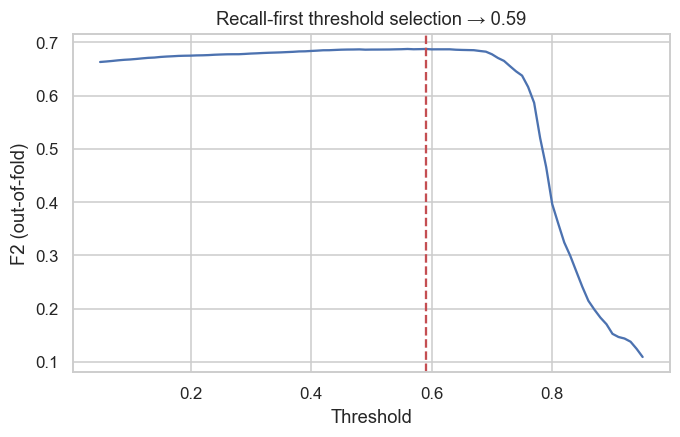

In [17]:
# Decision threshold: maximise F2 (recall weighted 2x precision) on OUT-OF-FOLD predictions — never on the test set
oof_best = cross_val_predict(best_model, X_train, y_train, cv=cv, groups=g_train, method="predict_proba")[:, 1]
ths = np.linspace(0.05, 0.95, 91)
f2s = [fbeta_score(y_train, (oof_best >= t).astype(int), beta=2) for t in ths]
THRESHOLD = float(ths[int(np.argmax(f2s))])
plt.figure(figsize=(7, 4)); plt.plot(ths, f2s); plt.axvline(THRESHOLD, color="r", ls="--"); plt.xlabel("Threshold"); plt.ylabel("F2 (out-of-fold)")
plt.title(f"Recall-first threshold selection → {THRESHOLD:.2f}"); plt.show()

,PR-AUC,ROC-AUC,Recall,Precision,F1,F2,MCC
Model,,,,,,,
Tuned XGBoost @ 0.50,0.4796,0.908,0.9924,0.3087,0.4709,0.6877,0.4832
Tuned XGBoost @ 0.59 (recall-first),0.4796,0.908,0.9878,0.3119,0.4741,0.6891,0.4852


At threshold 0.59: 30.1% of objects are flagged for review; they contain 98.8% of all hazardous objects (precision 31.2%) -> analysts review ~3.2 flagged objects per true hazard.


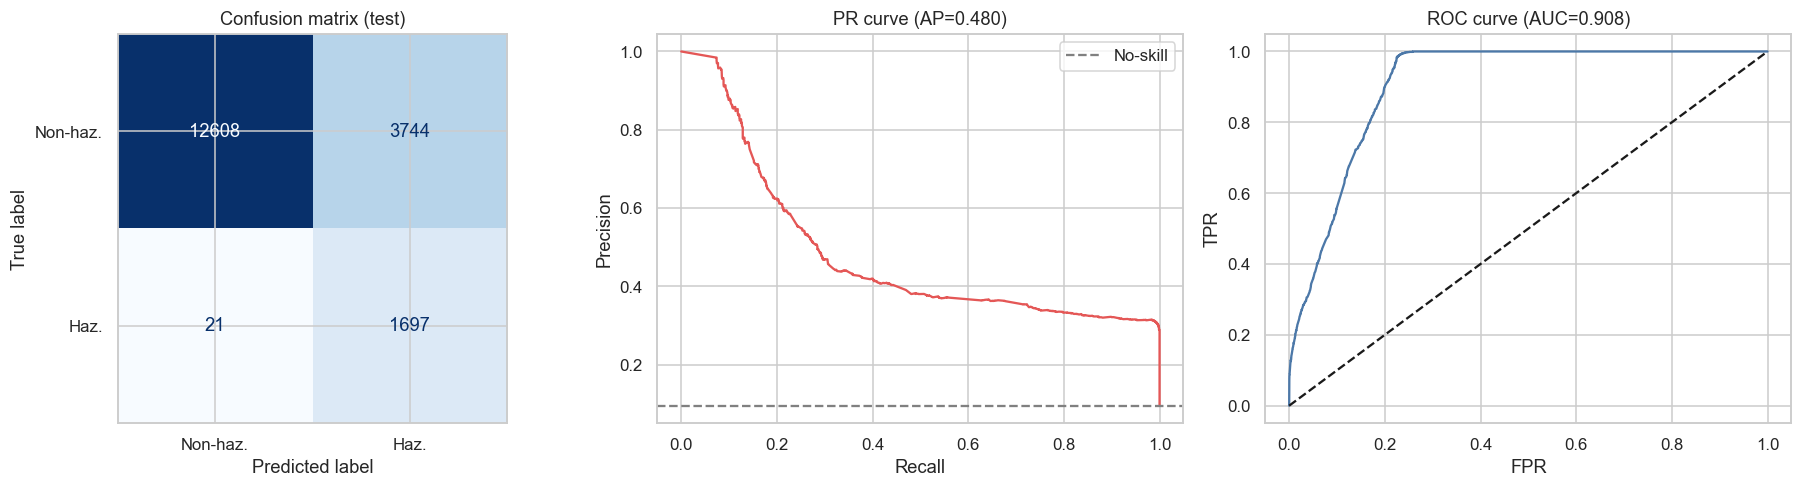

In [18]:
# Final evaluation on the held-out test set
best_model.fit(X_train, y_train)
p_test = best_model.predict_proba(X_test)[:, 1]
final = pd.DataFrame([
    metrics("Tuned XGBoost @ 0.50", y_test, p_test, 0.5),
    metrics(f"Tuned XGBoost @ {THRESHOLD:.2f} (recall-first)", y_test, p_test, THRESHOLD),
]).set_index("Model").round(4)
display(final)
flag = (p_test >= THRESHOLD)
print(f"At threshold {THRESHOLD:.2f}: {flag.mean():.1%} of objects are flagged for review; they contain {recall_score(y_test, flag):.1%} of all hazardous objects "
      f"(precision {precision_score(y_test, flag):.1%}) -> analysts review ~{flag.sum()/max(1,y_test[flag].sum()):.1f} flagged objects per true hazard.")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= THRESHOLD).astype(int)), display_labels=["Non-haz.", "Haz."]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (test)")
pr, rc, _ = precision_recall_curve(y_test, p_test); ax[1].plot(rc, pr, color="#E45756"); ax[1].axhline(y_test.mean(), color="gray", ls="--", label="No-skill")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("PR curve (AP=%.3f)" % average_precision_score(y_test, p_test)); ax[1].legend()
fpr, tpr, _ = roc_curve(y_test, p_test); ax[2].plot(fpr, tpr, color="#4C78A8"); ax[2].plot([0, 1], [0, 1], "k--")
ax[2].set_xlabel("FPR"); ax[2].set_ylabel("TPR"); ax[2].set_title("ROC curve (AUC=%.3f)" % roc_auc_score(y_test, p_test)); plt.tight_layout(); plt.show()

**Model-development takeaways**
- Plain accuracy is useless here; the dummy model gets ~90% accuracy with 0 recall.
- Gradient-boosted trees beat linear models and the hand-written rule, confirming the non-linear, multi-factor nature of the problem.
- Class weighting + a threshold chosen for recall lets the model **catch ~99% of hazardous objects**, at the cost of many false alarms (it effectively flags large objects, then ranks them by proximity/velocity) — the right trade-off for planetary defence, where a missed hazard is far costlier than an extra review.
- Scores are bounded by missing information (see Phase 5): the official label uses an orbit-intersection distance (MOID) that is not in this CSV.

---
## Phase 5 — Explainability & Visualization

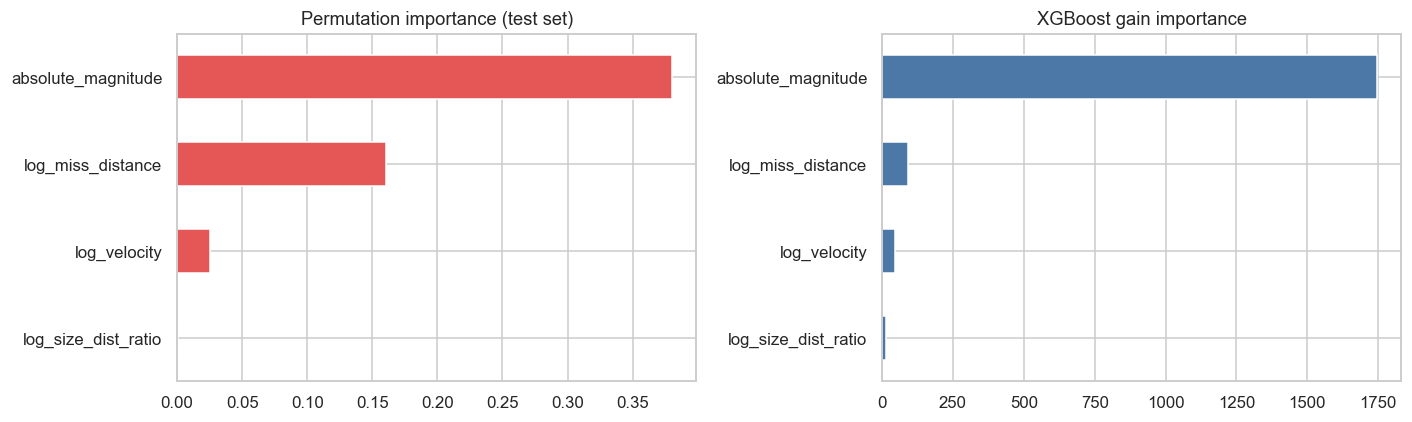

,Permutation (ΔPR-AUC),XGBoost gain
absolute_magnitude,0.3799,1744.7758
log_miss_distance,0.1606,90.1482
log_velocity,0.0256,45.4301
log_size_dist_ratio,0.0006,12.9191


In [19]:
perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"Permutation (ΔPR-AUC)": perm.importances_mean, "XGBoost gain": best_model.get_booster().get_score(importance_type="gain")}, index=X.columns
                   ).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
imp["Permutation (ΔPR-AUC)"].sort_values().plot(kind="barh", ax=ax[0], color="#E45756")
ax[0].set_title("Permutation importance (test set)")
imp["XGBoost gain"].sort_values().plot(kind="barh", ax=ax[1], color="#4C78A8"); ax[1].set_title("XGBoost gain importance"); plt.tight_layout(); plt.show()
imp.sort_values("Permutation (ΔPR-AUC)", ascending=False).round(4)

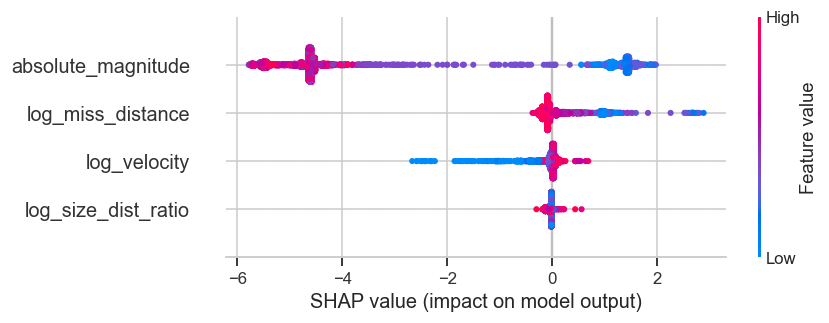

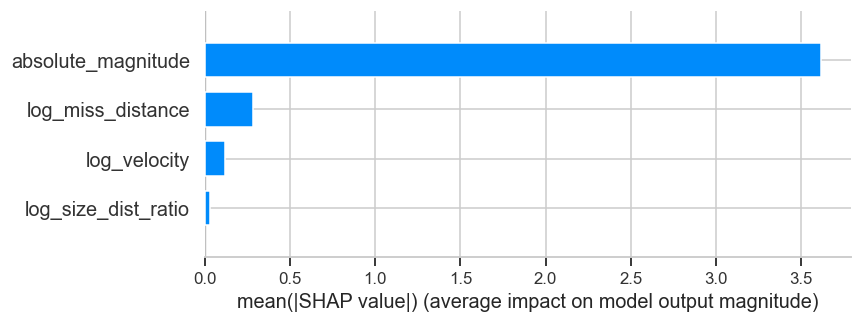

In [20]:
explainer = shap.TreeExplainer(best_model)
X_shap = X_test.sample(3000, random_state=SEED)
sv = explainer.shap_values(X_shap)
shap.summary_plot(sv, X_shap, show=True)
shap.summary_plot(sv, X_shap, plot_type="bar", show=True)

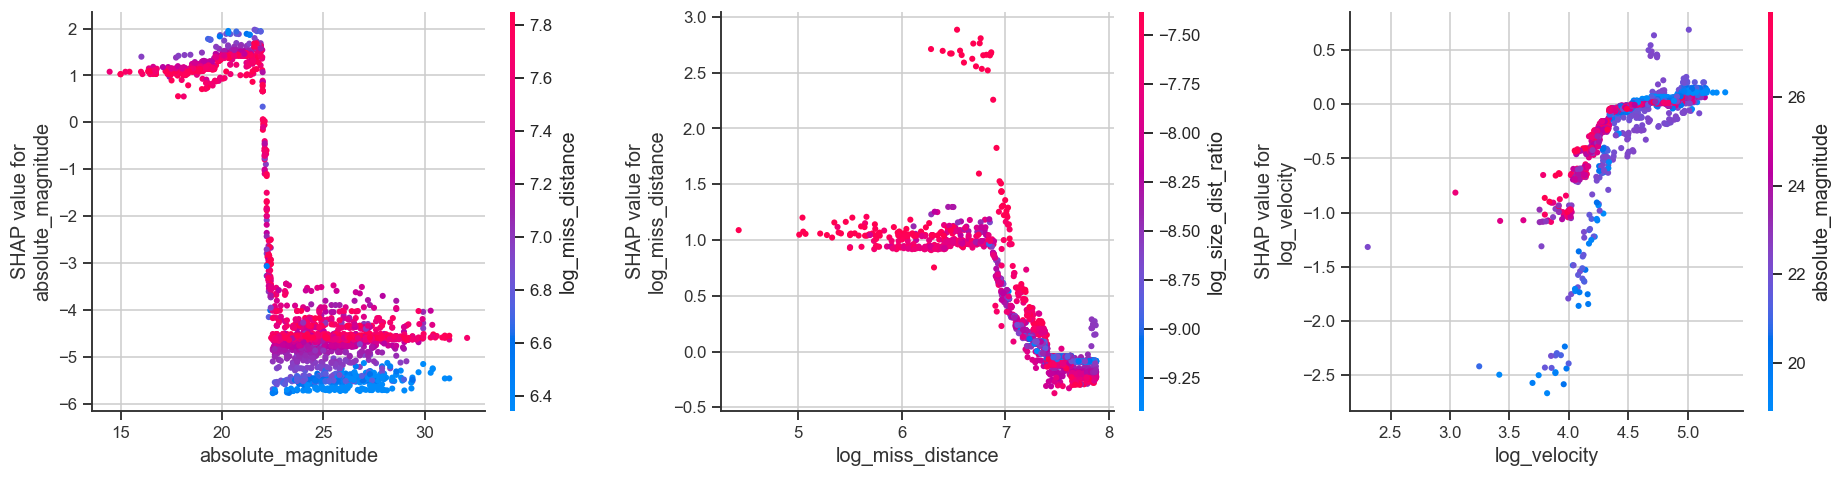

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, f in zip(ax, ["absolute_magnitude", "log_miss_distance", "log_velocity"]):
    shap.dependence_plot(f, sv, X_shap, ax=a, show=False)
plt.tight_layout(); plt.show()

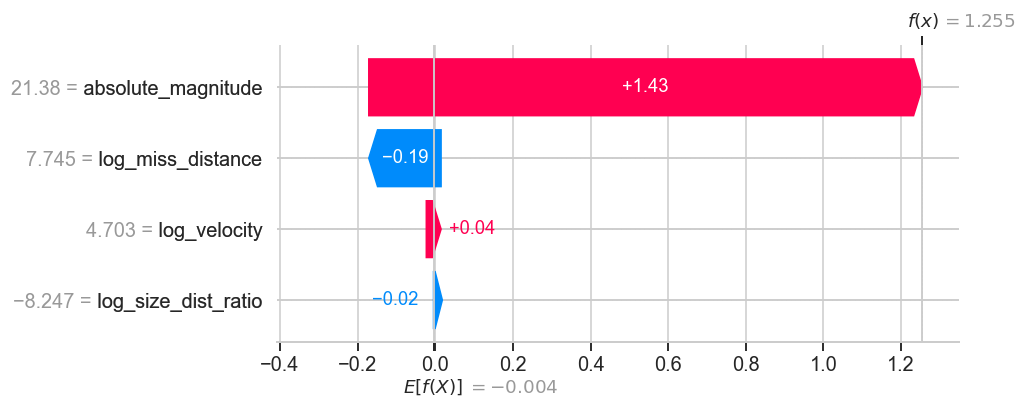

Predicted hazard probability: 0.778


In [22]:
# Explain individual predictions (what a scientist would ask: "why was THIS object flagged?")
idx_h = X_test.index[(y_test.values == 1) & (p_test >= THRESHOLD)][0]
ex = explainer(X_test.loc[[idx_h]])
shap.plots.waterfall(ex[0], show=True)
print("Predicted hazard probability: %.3f" % best_model.predict_proba(X_test.loc[[idx_h]])[0, 1])

### Scientific interpretation
- **Absolute magnitude (size) is by far the strongest indicator.** Hazard requires a large object: NASA's Potentially Hazardous Asteroid definition starts with H ≤ 22 (≈ 140 m or larger), and the SHAP dependence plot shows a cliff right at that value (predicted risk collapses to ~0 for H > 22) — the model rediscovered the physical threshold from data alone.
- **Proximity and velocity are secondary but real signals.** Closer approaches push the prediction up *only for large objects* (e.g. an H = 18 object scores ≈0.99 at 1 million km vs ≈0.70 at 60 million km); for small ones (H > 22) distance changes nothing. This is the multi-factor interaction described in the brief, which a one-feature rule cannot represent.
- **Why performance plateaus:** the official hazardous flag is defined using the orbit's *minimum orbit intersection distance* (MOID ≤ 0.05 AU), a property of the whole orbit, whereas `miss_distance` describes a single flyby. Two big asteroids with similar flybys can have different labels. Adding orbital elements (a, e, i) is the natural next step — see the optional enrichment below.

---
## Phase 6 — Deployment

In [23]:
os.makedirs("artifacts", exist_ok=True)
artifact = {"model": best_model, "features": FEATURES, "threshold": THRESHOLD, "ld_km": LD_KM}
joblib.dump(artifact, "artifacts/sentinel_model.joblib")
with open("artifacts/model_card.json", "w") as f:
    json.dump({"features": FEATURES, "threshold": THRESHOLD, "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
               "test_metrics": final.reset_index().to_dict(orient="records")}, f, indent=2, default=float)
print("Saved:", os.listdir("artifacts"))

Saved: ['model_card.json', 'sentinel_model.joblib']


In [24]:
# Reload + prediction function (inputs are the raw physical quantities a researcher would have)
art = joblib.load("artifacts/sentinel_model.joblib")

def diameter_from_H(H, albedo=0.14):
    # standard NASA/JPL relation: D(km) = 1329 / sqrt(albedo) * 10^(-H/5)
    return 1329 / np.sqrt(albedo) * 10 ** (-H / 5)

def predict_neo(absolute_magnitude, relative_velocity_kmh, miss_distance_km):
    d = diameter_from_H(absolute_magnitude)
    row = pd.DataFrame([{
        "absolute_magnitude": absolute_magnitude,
        "log_velocity": np.log10(relative_velocity_kmh),
        "log_miss_distance": np.log10(miss_distance_km),
        "log_size_dist_ratio": np.log10(d / miss_distance_km)}])[art["features"]]
    p = float(art["model"].predict_proba(row)[0, 1])
    label = "HAZARDOUS" if p >= art["threshold"] else "NON-HAZARDOUS"
    return label, p, d

# sanity check on one correctly-classified hazardous and one non-hazardous test row
pred_test = (p_test >= art["threshold"]).astype(int)
for lbl in (1, 0):
    i = X_test.index[(y_test.values == lbl) & (pred_test == lbl)][0]
    r = data.loc[i]
    print("true =", lbl, "->", predict_neo(r.absolute_magnitude, r.relative_velocity, r.miss_distance)[:2])

true = 1 -> ('HAZARDOUS', 0.7781517505645752)
true = 0 -> ('NON-HAZARDOUS', 0.00917132943868637)


In [25]:
import gradio as gr

def ui_predict(H, velocity_kmh, miss_km):
    if H is None or velocity_kmh is None or miss_km is None or velocity_kmh <= 0 or miss_km <= 0:
        return "Please enter positive values.", {}, ""
    label, p, d = predict_neo(H, velocity_kmh, miss_km)
    icon = "🔴" if label == "HAZARDOUS" else "🟢"
    return f"{icon} {label}", {"Hazardous": p, "Non-hazardous": 1 - p}, \
           f"Est. diameter ≈ {d*1000:,.0f} m | miss distance ≈ {miss_km/LD_KM:,.1f} lunar distances | decision threshold = {art['threshold']:.2f}"

demo = gr.Interface(
    fn=ui_predict,
    inputs=[gr.Number(value=20.0, label="Absolute magnitude (H)"),
            gr.Number(value=60000, label="Relative velocity (km/h)"),
            gr.Number(value=20_000_000, label="Miss distance (km)")],
    outputs=[gr.Textbox(label="Classification"), gr.Label(label="Probability"), gr.Textbox(label="Derived info")],
    examples=[[17.5, 90000, 5_000_000], [20.0, 60000, 20_000_000], [26.0, 40000, 50_000_000]],
    title="🛰️ Project Sentinel — Hazardous Asteroid Classifier",
    description="Enter a Near-Earth Object's characteristics to predict whether it should be flagged as hazardous.")

if os.environ.get("NEO_SKIP_UI") != "1":
    demo.launch()   # in Colab add share=True for a public link

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


---
## 🔧 Optional bonus — enrich with real orbital elements from NASA JPL
The brief lists *orbital parameters* as inputs, but the supplied CSV has none. This optional cell pulls semi-major axis, eccentricity and inclination from the JPL Small-Body Database (internet required) and re-trains. **MOID and the official PHA flag are deliberately excluded** — they would leak the label.
Set `ENRICH = True` to run it. If the download fails, the notebook simply carries on.

In [26]:
ENRICH = False
if ENRICH:
    try:
        import requests
        url = "https://ssd-api.jpl.nasa.gov/sbdb_query.api"
        r = requests.get(url, params={"fields": "spkid,a,e,i", "sb-kind": "a", "sb-group": "neo"}, timeout=120).json()
        orb = pd.DataFrame(r["data"], columns=r["fields"]).astype(float).rename(columns={"spkid": "id"})
        orb["id"] = orb["id"].astype(int)
        enr = df[["id"]].merge(orb, on="id", how="left")
        print("Matched asteroids with orbital elements: %.1f%%" % (100 * enr["a"].notna().mean()))
        X2 = X.copy(); X2[["a", "e", "i"]] = enr[["a", "e", "i"]].values
        X2 = X2.fillna(X2.median())
        m2 = XGBClassifier(**{k: v for k, v in search.best_params_.items()}, scale_pos_weight=pos_weight, eval_metric="aucpr", n_jobs=-1, random_state=SEED)
        m2.fit(X2.iloc[train_idx], y_train)
        p2 = m2.predict_proba(X2.iloc[test_idx])[:, 1]
        print("PR-AUC  baseline: %.3f  ->  with orbital elements: %.3f" % (average_precision_score(y_test, p_test), average_precision_score(y_test, p2)))
    except Exception as e:
        print("Enrichment skipped:", e)
else:
    print("Enrichment disabled (set ENRICH = True to run).")

Enrichment disabled (set ENRICH = True to run).


---
## ✅ Conclusion
- Built a leakage-safe, imbalance-aware classifier (grouped splits, PR-AUC, recall-first threshold).
- Showed that a hand-written rule fails while a tuned gradient-boosting model captures the multi-factor structure.
- Explained predictions with permutation importance and SHAP; size (absolute magnitude) dominates, proximity/velocity refine it.
- Identified the data's ceiling (missing MOID/orbital elements) and provided a path to improve it.
- Deployed the model as a saved artifact and an interactive Gradio app.